In [3]:
from pathlib import Path
from collections import Counter
import pandas as pd
from itertools import combinations
import hashlib
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
from functools import lru_cache
from skimage.metrics import structural_similarity
from IPython.display import clear_output, display

In [ ]:
SEED = 42
DATA_DIR = Path(r"C:\Users\kubaa\ProjektZUM\Dane")
REVIEW_FILE = Path(r".\results\pair_decisions.csv")

In [5]:
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Nie znaleziono katalogu: {DATA_DIR}")

print("Katalog główny")
for path in sorted(DATA_DIR.iterdir()):
    print(path.name + ("/" if path.is_dir() else ""))

print("\nManifesty i metadane")
for pattern in ("*.txt", "*.csv", "*.json"):
    for path in sorted(DATA_DIR.rglob(pattern)):
        if path.is_file():
            print(path.relative_to(DATA_DIR))

Katalog główny
audit_review/
test/
test.txt
train/
train.txt
val/
val.txt

Manifesty i metadane
test.txt
train.txt
val.txt
audit_review\pair_decisions.csv


In [6]:
MANIFESTS = {
    "train": DATA_DIR / "train.txt",
    "validation": DATA_DIR / "val.txt",
    "test": DATA_DIR / "test.txt",
}

for split, path in MANIFESTS.items():
    with path.open(encoding="utf-8-sig") as file:
        rows = [line.split() for line in file if line.strip()]

    print(f"\n{split} ({path.name})")
    print("Liczba niepustych wierszy:", len(rows))
    print("Liczba pól → liczba wierszy:", dict(Counter(map(len, rows))))
    print("Pola od trzeciego wzwyż:", [row[2:] for row in rows[:3]])


train (train.txt)
Liczba niepustych wierszy: 67863
Liczba pól → liczba wierszy: {4: 67863}
Pola od trzeciego wzwyż: [['negative', 'cohen'], ['negative', 'cohen'], ['negative', 'cohen']]

validation (val.txt)
Liczba niepustych wierszy: 8473
Liczba pól → liczba wierszy: {4: 8473}
Pola od trzeciego wzwyż: [['positive', 'actmed'], ['positive', 'actmed'], ['positive', 'bimcv']]

test (test.txt)
Liczba niepustych wierszy: 8482
Liczba pól → liczba wierszy: {4: 8482}
Pola od trzeciego wzwyż: [['positive', 'ricord'], ['positive', 'ricord'], ['positive', 'ricord']]


In [7]:
IMAGE_DIRS = {
    "train": DATA_DIR / "train",
    "validation": DATA_DIR / "val",
    "test": DATA_DIR / "test",
}

COLUMNS = ["patient_id", "filename", "label", "source"]

frames = []
for split, path in MANIFESTS.items():
    frame = pd.read_csv(
        path,
        sep=r"\s+",
        header=None,
        names=COLUMNS,
        dtype="string",
        encoding="utf-8-sig",
        keep_default_na=False,
    )
    frame["split"] = split
    frame["file_exists"] = frame["filename"].map(
        lambda name: (IMAGE_DIRS[split] / name).is_file()
    )
    frames.append(frame)

data = pd.concat(frames, ignore_index=True)

summary = data.groupby("split", sort=False).agg(
    wpisy=("filename", "size"),
    unikalne_nazwy_plikow=("filename", "nunique"),
    unikalne_id_pacjentow=("patient_id", "nunique"),
    znalezione_pliki=("file_exists", "sum"),
)
summary["brakujace_pliki"] = summary["wpisy"] - summary["znalezione_pliki"]

display(summary)

,wpisy,unikalne_nazwy_plikow,unikalne_id_pacjentow,znalezione_pliki,brakujace_pliki
split,,,,,
train,67863,67863,35457,67863,0
validation,8473,8473,5163,8473,0
test,8482,8482,4722,8482,0


In [8]:
class_counts = pd.crosstab(data["split"], data["label"])
class_percentages = class_counts.div(class_counts.sum(axis=1), axis=0) * 100

display(class_counts)
display(class_percentages.round(2))

source_counts = pd.crosstab([data["split"], data["source"]], data["label"])
display(source_counts)

label,negative,positive
split,,
test,4241,4241
train,10664,57199
validation,4232,4241


label,negative,positive
split,,
test,50.00,50.00
train,15.71,84.29
validation,49.95,50.05


label                  negative  positive
split      source                        
test       bimcv           4041      4041
           ricord             0       200
           rsna             200         0
train      actmed            78        23
           bimcv            647     42495
           cohen            220       251
           fig1               0        22
           ricord             0       834
           rsna            9719         0
           sirm               0       878
           stonybrook         0     12696
validation actmed            29         2
           bimcv            257      3151
           cohen             77        19
           fig1               0         2
           ricord             0        62
           rsna            3869         0
           sirm               0        65
           stonybrook         0       940

In [9]:
patient_ids = {
    split: set(group["patient_id"].dropna()) - {""}
    for split, group in data.groupby("split", sort=False)
}

for left, right in combinations(patient_ids, 2):
    shared_ids = patient_ids[left] & patient_ids[right]
    print(f"{left} × {right}: {len(shared_ids)} wspólnych ID")

print(
    "Unikalne ID w całym zbiorze:",
    len(set().union(*patient_ids.values())),
)

train × validation: 0 wspólnych ID
train × test: 0 wspólnych ID
validation × test: 0 wspólnych ID
Unikalne ID w całym zbiorze: 45342


### Braki danych / nieczytelne pliki oraz Duplikaty

In [10]:
def inspect_image(path):
    with path.open("rb") as file:
        file_hash = hashlib.file_digest(file, "sha256").hexdigest()

    with Image.open(path) as image:
        image.load()
        width, height = image.size
        mode = image.mode

        pixel_hash = hashlib.sha256(
            f"{mode}:{width}x{height}:".encode()
        )
        pixel_hash.update(image.tobytes())

    return file_hash, pixel_hash.hexdigest(), width, height, mode

records = []
for number, row in enumerate(data.itertuples(index=False), start=1):
    path = IMAGE_DIRS[row.split] / row.filename

    try:
        file_hash, pixel_hash, width, height, mode = inspect_image(path)
        records.append((file_hash, pixel_hash, width, height, mode, None))
    except (OSError, ValueError, Image.DecompressionBombError) as error:
        records.append((None, None, None, None, None, type(error).__name__))

    if number % 10_000 == 0:
        print(f"Sprawdzono {number:,} / {len(data):,} plików")

audit = data.join(pd.DataFrame(
    records,
    index=data.index,
    columns=["file_hash", "pixel_hash", "width", "height", "mode", "error"],
))

display(audit.groupby("split")["error"].count().rename("nieczytelne_pliki"))
display(audit.groupby("split")[["width", "height"]].agg(["min", "median", "max"]))

Sprawdzono 10,000 / 84,818 plików
Sprawdzono 20,000 / 84,818 plików
Sprawdzono 30,000 / 84,818 plików
Sprawdzono 40,000 / 84,818 plików
Sprawdzono 50,000 / 84,818 plików
Sprawdzono 60,000 / 84,818 plików
Sprawdzono 70,000 / 84,818 plików
Sprawdzono 80,000 / 84,818 plików


split
test          0
train         0
validation    0
Name: nieczytelne_pliki, dtype: int64

width               height              
             min  median   max    min  median   max
split                                              
test         761  1024.0  1024    553   843.0  1024
train        157  1024.0  1024    156   843.0  1024
validation   256  1024.0  1024    256  1024.0  1024

In [11]:
for column in ("file_hash", "pixel_hash"):
    groups = audit.dropna(subset=[column]).groupby(column).agg(
        images=("split", "size"),
        splits=("split", "nunique"),
        patients=("patient_id", "nunique"),
        labels=("label", "nunique"),
    )
    duplicates = groups[groups["images"] > 1]

    print(f"\n{column}")
    print("Grupy duplikatów:", len(duplicates))
    print("Zdjęcia w tych grupach:", duplicates["images"].sum())
    print("Grupy w więcej niż jednym podzbiorze:", (duplicates["splits"] > 1).sum())
    print("Grupy z różnymi ID pacjentów:", (duplicates["patients"] > 1).sum())
    print("Grupy ze sprzecznymi etykietami:", (duplicates["labels"] > 1).sum())


file_hash
Grupy duplikatów: 48
Zdjęcia w tych grupach: 100
Grupy w więcej niż jednym podzbiorze: 2
Grupy z różnymi ID pacjentów: 7
Grupy ze sprzecznymi etykietami: 1

pixel_hash
Grupy duplikatów: 48
Zdjęcia w tych grupach: 100
Grupy w więcej niż jednym podzbiorze: 2
Grupy z różnymi ID pacjentów: 7
Grupy ze sprzecznymi etykietami: 1


In [12]:
duplicate_rows = audit[audit["file_hash"].notna()].copy()
by_hash = duplicate_rows.groupby("file_hash", sort=False)

duplicate_rows["group"] = by_hash.ngroup() + 1
duplicate_rows["n_splits"] = by_hash["split"].transform("nunique")
duplicate_rows["n_labels"] = by_hash["label"].transform("nunique")

conflicts = duplicate_rows.loc[
    (duplicate_rows["n_splits"] > 1) | (duplicate_rows["n_labels"] > 1)
]

display(
    conflicts.groupby(["group", "split", "source", "label"], dropna=False)
    .size()
    .rename("liczba_wpisow")
    .reset_index()
)

,group,split,source,label,liczba_wpisow
0,27008,test,bimcv,positive,1
1,27008,train,bimcv,positive,1
2,68355,test,bimcv,positive,1
3,68355,validation,bimcv,positive,1
4,79314,test,bimcv,negative,1
5,79314,test,bimcv,positive,1


In [13]:
# Wykluczamy wszystkie wpisy z grup o sprzecznych etykietach.
labels_per_image = audit.groupby("pixel_hash")["label"].transform("nunique")
clean = audit.loc[audit["error"].isna() & labels_per_image.eq(1)].copy()

# Przy zgodnych etykietach zachowujemy jedną kopię.
# Kolejność nazw plików rozstrzyga remis w obrębie podzbioru.
split_priority = {"test": 0, "validation": 1, "train": 2}
clean["priority"] = clean["split"].map(split_priority)

clean = (
    clean.sort_values(["priority", "filename"])
    .drop_duplicates(subset="pixel_hash", keep="first")
    .drop(columns="priority")
)

assert clean["pixel_hash"].is_unique
assert clean["file_hash"].is_unique
assert clean.groupby("patient_id")["split"].nunique().le(1).all()

display(
    clean.groupby("split").agg(
        zdjecia=("filename", "size"),
        unikalne_id_pacjentow=("patient_id", "nunique"),
    ).reindex(["train", "validation", "test"])
)

display(
    pd.crosstab(clean["split"], clean["label"])
    .reindex(["train", "validation", "test"])
)

print("Wykluczone wpisy:", len(audit) - len(clean))

,zdjecia,unikalne_id_pacjentow
split,,
train,67838,35456
validation,8461,5163
test,8466,4722


label,negative,positive
split,,
train,10663,57175
validation,4232,4229
test,4237,4229


Wykluczone wpisy: 53


In [14]:
metadata_columns = ["patient_id", "filename", "label", "source"]
missing_markers = {"", "na", "nan", "none", "null", "unknown", "-"}

missing_metadata = pd.DataFrame({
    column: (
        clean[column].isna()
        | clean[column].str.strip().str.lower().isin(missing_markers)
    )
    for column in metadata_columns
})

display(
    missing_metadata.groupby(clean["split"])
    .sum()
    .reindex(["train", "validation", "test"])
)

print("Etykiety:", sorted(clean["label"].unique()))

source_counts_clean = pd.crosstab(
    [clean["split"], clean["source"]],
    clean["label"],
)
display(source_counts_clean)

,patient_id,filename,label,source
split,,,,
train,0,0,0,0
validation,0,0,0,0
test,0,0,0,0


Etykiety: ['negative', 'positive']


label                  negative  positive
split      source                        
test       bimcv           4037      4029
           ricord             0       200
           rsna             200         0
train      actmed            78        23
           bimcv            647     42477
           cohen            219       251
           fig1               0        22
           ricord             0       828
           rsna            9719         0
           sirm               0       878
           stonybrook         0     12696
validation actmed            29         2
           bimcv            257      3142
           cohen             77        19
           fig1               0         2
           ricord             0        61
           rsna            3869         0
           sirm               0        65
           stonybrook         0       938

### Przykładowe Obrazy

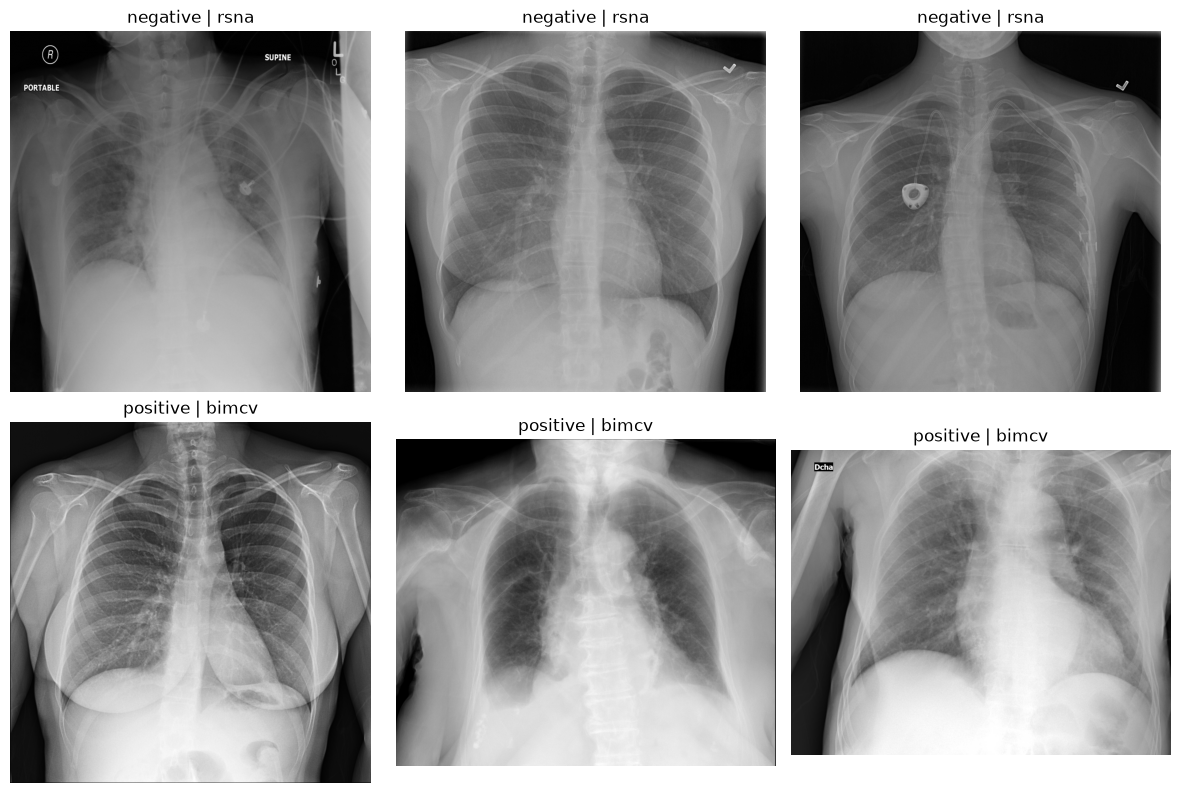

In [15]:
examples = pd.concat([
    clean.loc[
        (clean["split"] == "train") & (clean["label"] == label)
    ].sample(n=3, random_state=SEED)
    for label in ["negative", "positive"]
])

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, row in zip(axes.flat, examples.itertuples(index=False)):
    path = IMAGE_DIRS[row.split] / row.filename

    with Image.open(path) as image:
        ax.imshow(image.convert("L"), cmap="gray")

    ax.set_title(f"{row.label} | {row.source}")
    ax.axis("off")

plt.tight_layout()
plt.show()

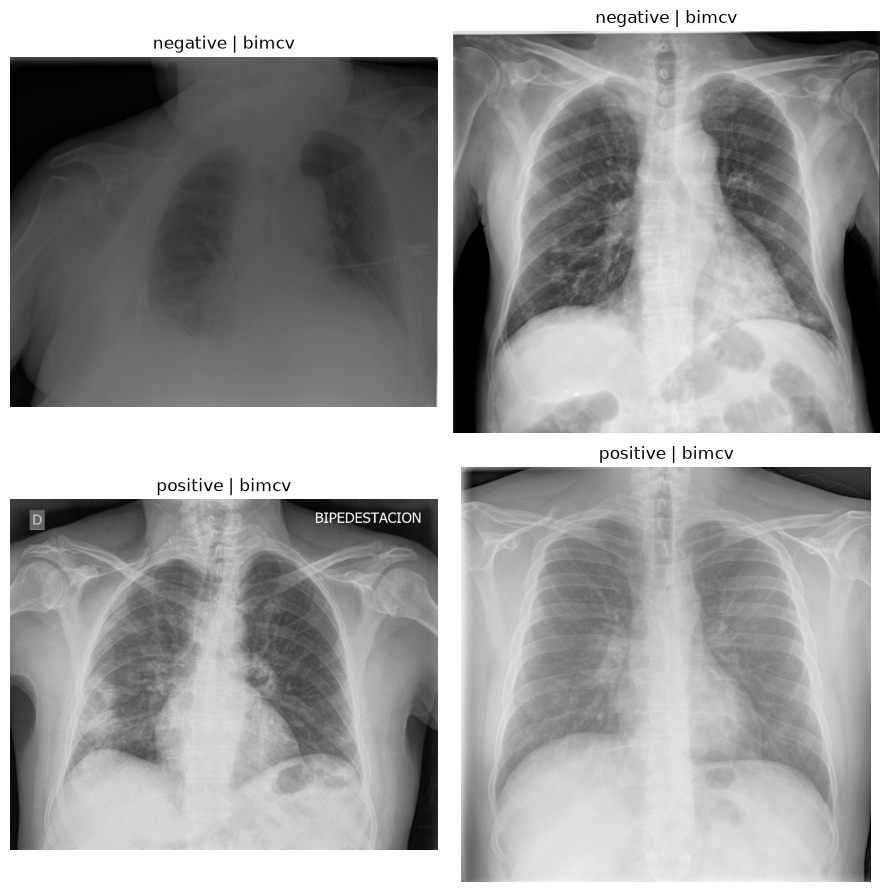

In [16]:
examples_bimcv = pd.concat([
    clean.loc[
        (clean["split"] == "train")
        & (clean["source"] == "bimcv")
        & (clean["label"] == label)
    ].sample(n=2, random_state=SEED)
    for label in ["negative", "positive"]
])

fig, axes = plt.subplots(2, 2, figsize=(9, 9))

for ax, row in zip(axes.flat, examples_bimcv.itertuples(index=False)):
    with Image.open(IMAGE_DIRS[row.split] / row.filename) as image:
        ax.imshow(image.convert("L"), cmap="gray")

    ax.set_title(f"{row.label} | {row.source}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### Duplikaty

In [17]:
def calculate_dhash(path):
    with Image.open(path) as image:
        thumbnail = image.convert("L").resize(
            (9, 8),
            Image.Resampling.LANCZOS,
        )
        pixels = np.asarray(thumbnail)

    differences = pixels[:, 1:] > pixels[:, :-1]
    return np.packbits(differences).tobytes().hex()


visual_audit = clean.copy()
hashes = []

for number, row in enumerate(
    visual_audit.itertuples(index=False),
    start=1,
):
    path = IMAGE_DIRS[row.split] / row.filename
    hashes.append(calculate_dhash(path))

    if number % 10_000 == 0:
        print(f"Sprawdzono {number:,} / {len(visual_audit):,}")

visual_audit["dhash"] = hashes

visual_groups = visual_audit.groupby("dhash").agg(
    zdjecia=("filename", "size"),
    podzbiory=("split", "nunique"),
    pacjenci=("patient_id", "nunique"),
    etykiety=("label", "nunique"),
)

candidates = visual_groups.loc[visual_groups["zdjecia"] > 1]

print("Grupy z identycznym dHash:", len(candidates))
print(
    "Grupy przekraczające granice podziału:",
    candidates["podzbiory"].gt(1).sum(),
)
print(
    "Grupy z różnymi etykietami:",
    candidates["etykiety"].gt(1).sum(),
)

Sprawdzono 10,000 / 84,765
Sprawdzono 20,000 / 84,765
Sprawdzono 30,000 / 84,765
Sprawdzono 40,000 / 84,765
Sprawdzono 50,000 / 84,765
Sprawdzono 60,000 / 84,765
Sprawdzono 70,000 / 84,765
Sprawdzono 80,000 / 84,765
Grupy z identycznym dHash: 1640
Grupy przekraczające granice podziału: 711
Grupy z różnymi etykietami: 631



Grupa 1 — zdjęć: 3


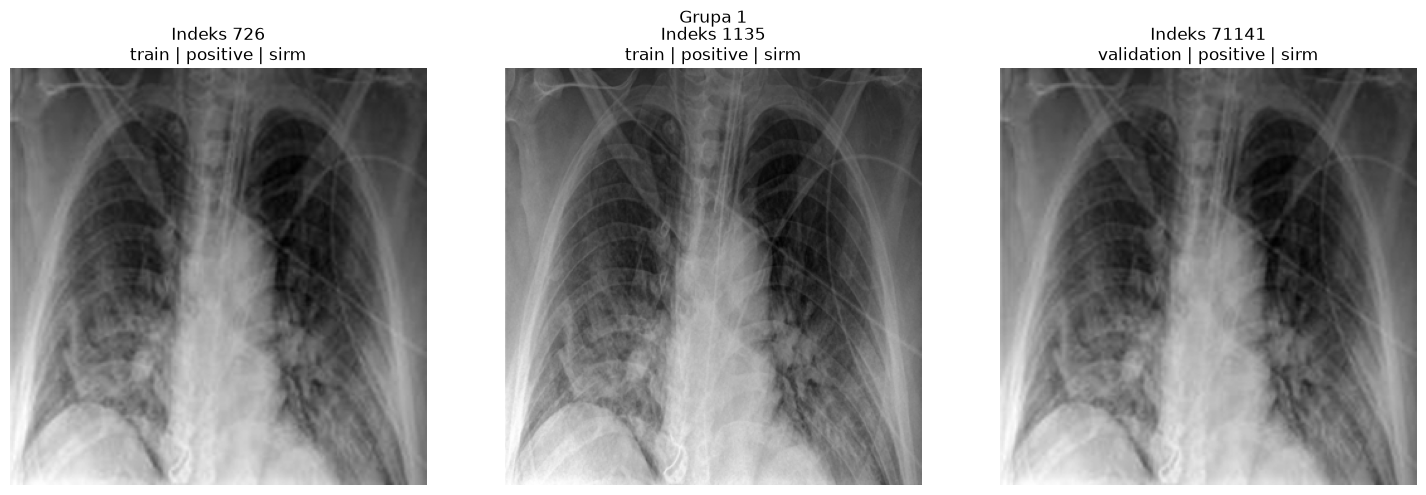


Grupa 2 — zdjęć: 3


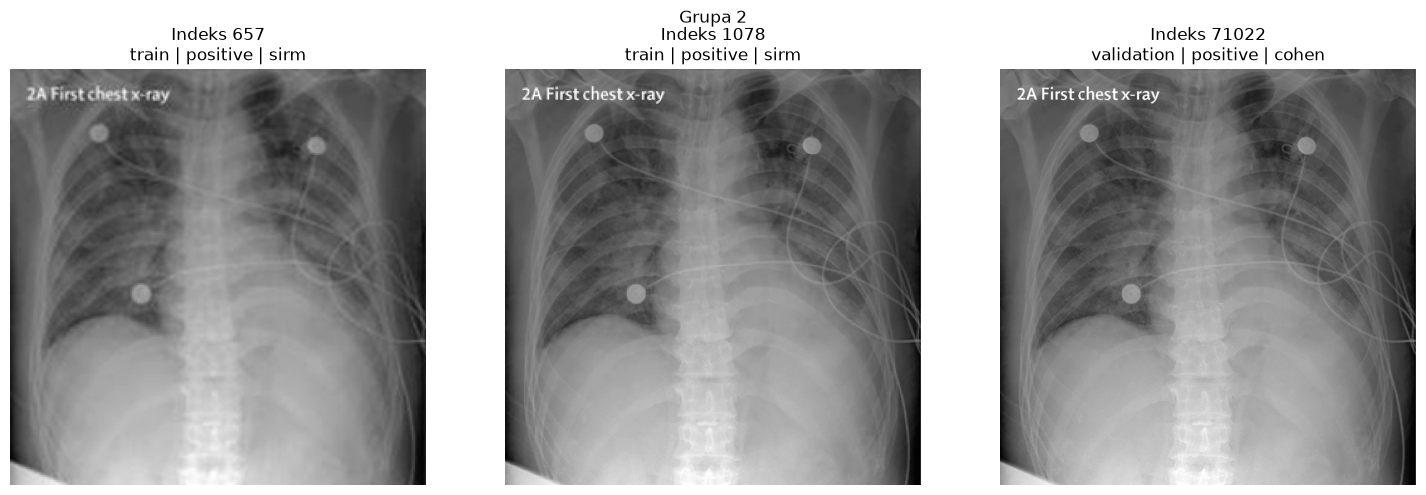


Grupa 3 — zdjęć: 3


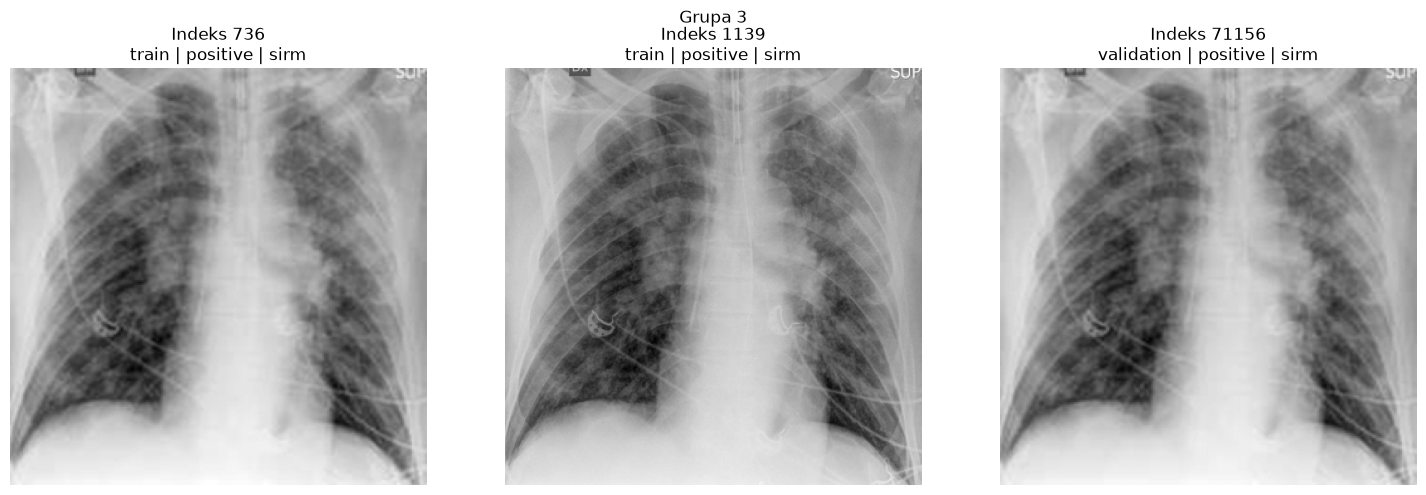


Grupa 4 — zdjęć: 3


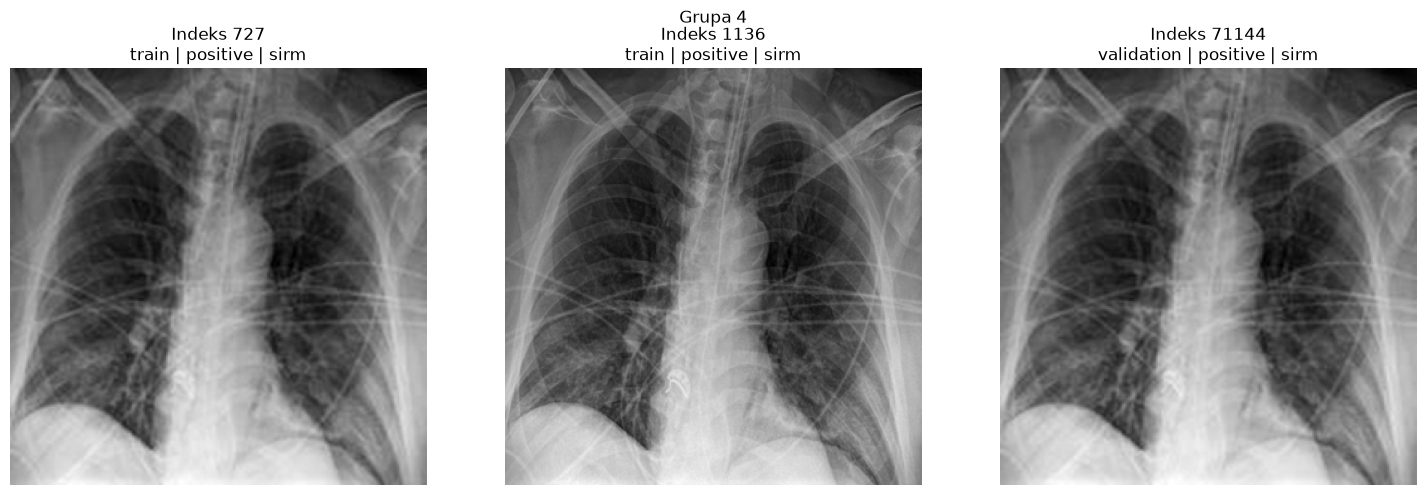


Grupa 5 — zdjęć: 2


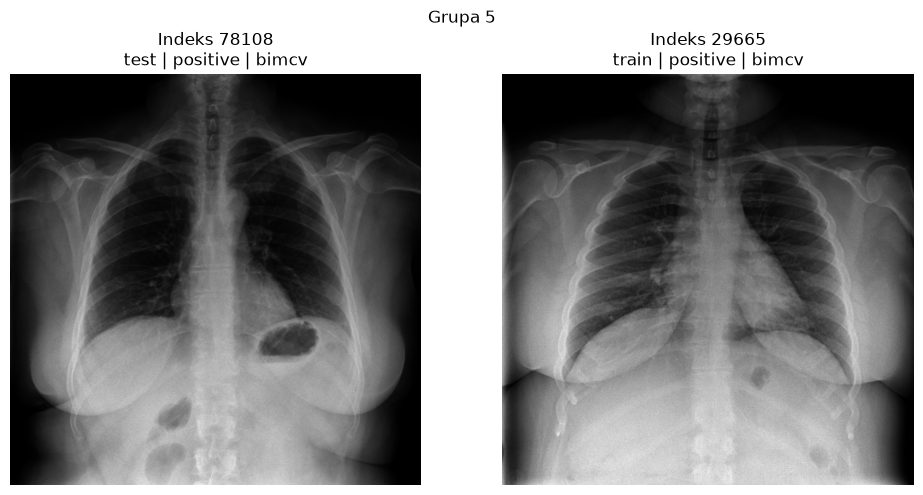


Grupa 6 — zdjęć: 3


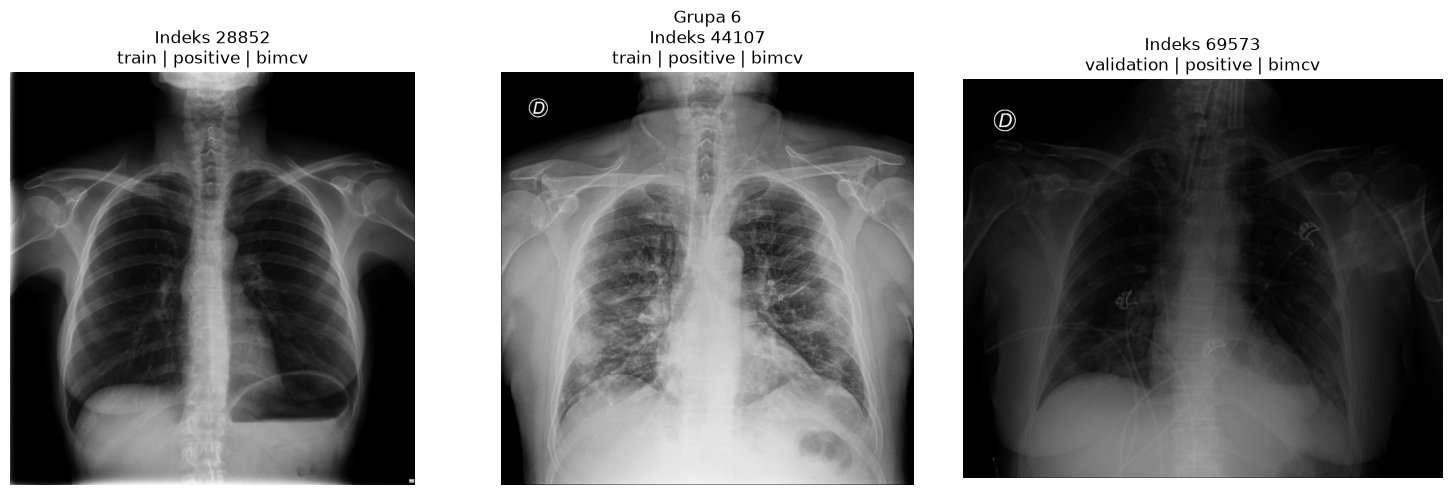

In [18]:
cross_split_hashes = candidates.loc[
    candidates["podzbiory"] > 1
].index

selected_hashes = sorted(cross_split_hashes)[:6]

for group_number, image_hash in enumerate(selected_hashes, start=1):
    group = (
        visual_audit.loc[visual_audit["dhash"] == image_hash]
        .sort_values(["split", "filename"])
    )

    print(f"\nGrupa {group_number} — zdjęć: {len(group)}")

    for start in range(0, len(group), 6):
        batch = group.iloc[start:start + 6]

        fig, axes = plt.subplots(
            1, len(batch),
            figsize=(5 * len(batch), 5),
            squeeze=False,
        )

        for ax, (index, row) in zip(axes.flat, batch.iterrows()):
            path = IMAGE_DIRS[row["split"]] / row["filename"]

            with Image.open(path) as image:
                ax.imshow(image.convert("L"), cmap="gray")

            ax.set_title(
                f"Indeks {index}\n"
                f"{row['split']} | {row['label']} | {row['source']}"
            )
            ax.axis("off")

        fig.suptitle(f"Grupa {group_number}")
        plt.tight_layout()
        plt.show()

In [19]:
REVIEW_SIZE = (256, 256)

@lru_cache(maxsize=256)
def load_review_image(split, filename):
    path = IMAGE_DIRS[split] / filename

    with Image.open(path) as image:
        thumbnail = image.convert("L").resize(
            REVIEW_SIZE,
            Image.Resampling.LANCZOS,
        )
        return np.asarray(thumbnail).copy()


cross_split_hashes = candidates.loc[
    candidates["podzbiory"] > 1
].index

candidate_images = visual_audit.loc[
    visual_audit["dhash"].isin(cross_split_hashes)
]

pair_count = 0

for _, group in candidate_images.groupby("dhash"):
    split_counts = group["split"].value_counts().tolist()
    pair_count += sum(
        left_count * right_count
        for left_count, right_count in combinations(split_counts, 2)
    )

print(f"Pary do porównania: {pair_count:,}")

pair_records = []

for image_hash, group in candidate_images.groupby("dhash", sort=True):
    rows = list(group.sort_index().iterrows())

    for (index_a, row_a), (index_b, row_b) in combinations(rows, 2):
        if row_a["split"] == row_b["split"]:
            continue

        image_a = load_review_image(row_a["split"], row_a["filename"])
        image_b = load_review_image(row_b["split"], row_b["filename"])

        score = structural_similarity(
            image_a,
            image_b,
            data_range=255,
        )

        pair_records.append({
            "index_a": index_a,
            "index_b": index_b,
            "split_a": row_a["split"],
            "split_b": row_b["split"],
            "filename_a": row_a["filename"],
            "filename_b": row_b["filename"],
            "label_a": row_a["label"],
            "label_b": row_b["label"],
            "source_a": row_a["source"],
            "source_b": row_b["source"],
            "dhash": image_hash,
            "ssim": float(score),
        })

        if len(pair_records) % 1_000 == 0:
            print(f"Porównano {len(pair_records):,} / {pair_count:,}")

ranking = pd.DataFrame(
    pair_records,
    columns=[
        "index_a", "index_b", "split_a", "split_b",
        "filename_a", "filename_b", "label_a", "label_b",
        "source_a", "source_b", "dhash", "ssim",
    ],
).sort_values(
    ["ssim", "index_a", "index_b"],
    ascending=[False, True, True],
).reset_index(drop=True)

load_review_image.cache_clear()

display(
    ranking[
        [
            "index_a", "index_b", "split_a", "split_b",
            "source_a", "source_b", "ssim",
        ]
    ].head(20)
)

Pary do porównania: 2,713
Porównano 1,000 / 2,713
Porównano 2,000 / 2,713


,index_a,index_b,split_a,split_b,source_a,source_b,ssim
0,1082,71026,train,validation,sirm,cohen,0.998004
1,1074,71018,train,validation,sirm,cohen,0.997559
2,1083,71027,train,validation,sirm,cohen,0.997421
3,1085,71029,train,validation,sirm,cohen,0.997373
4,1086,71030,train,validation,sirm,cohen,0.997297
5,1084,71028,train,validation,sirm,cohen,0.997282
6,1078,71022,train,validation,sirm,cohen,0.997082
7,1079,71023,train,validation,sirm,cohen,0.995964
8,1077,71021,train,validation,sirm,cohen,0.995891
9,1088,71034,train,validation,sirm,cohen,0.995520


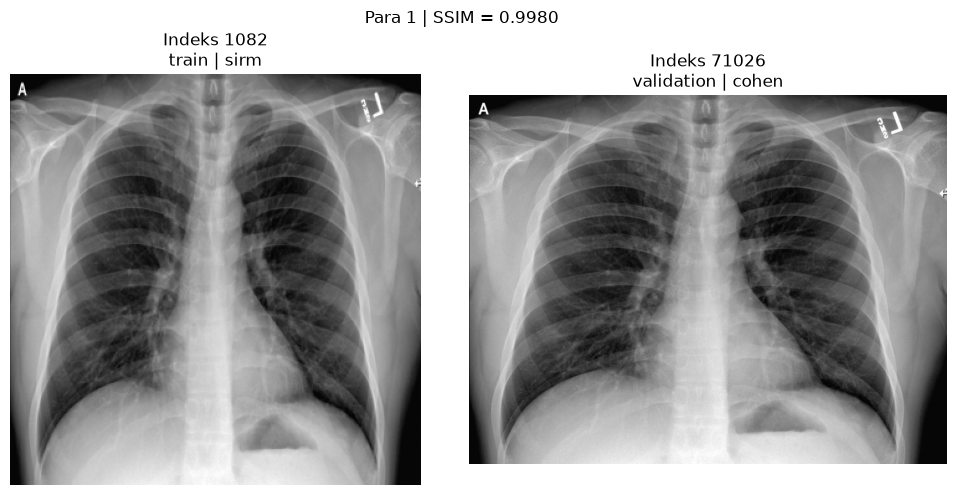

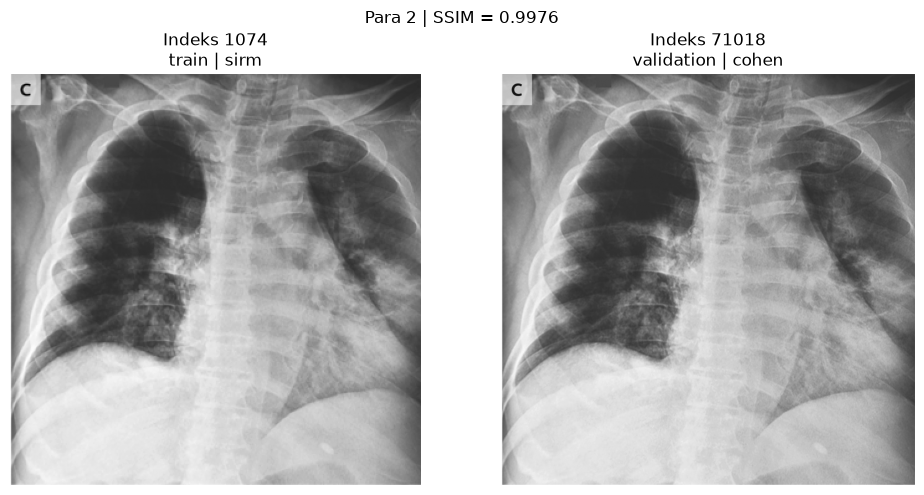

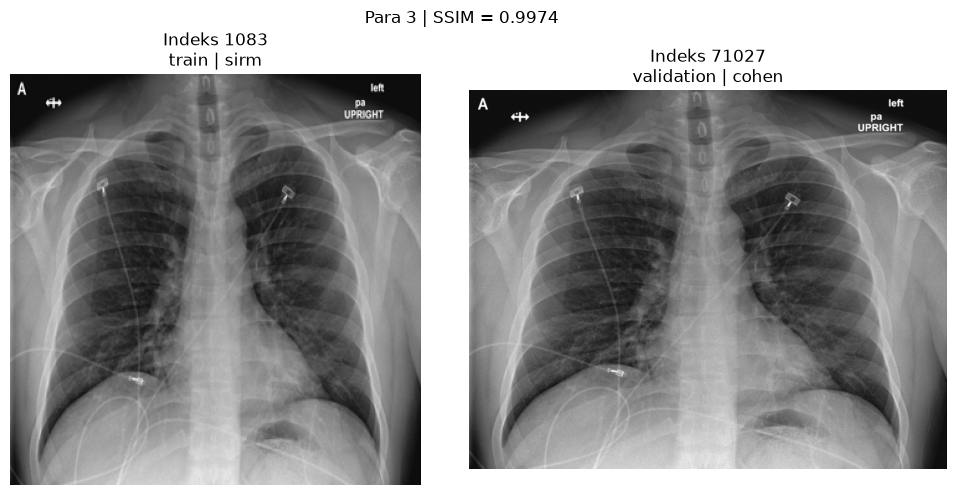

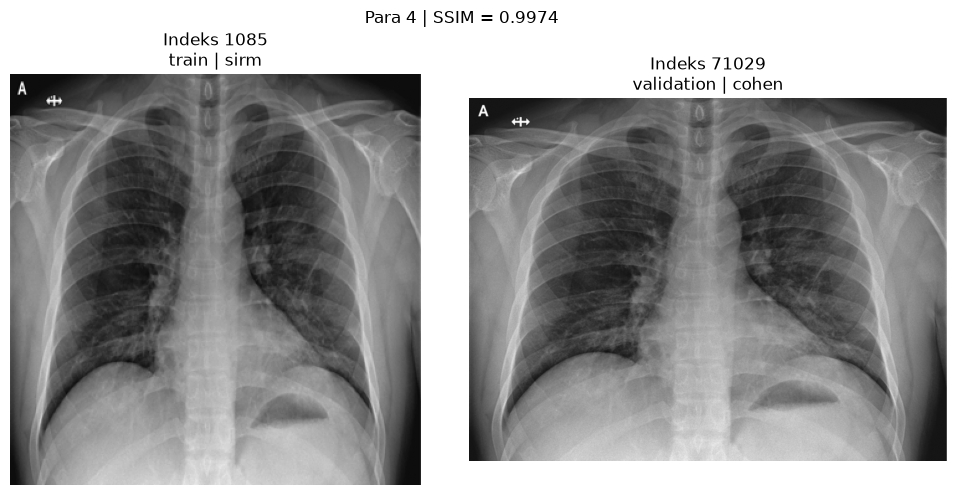

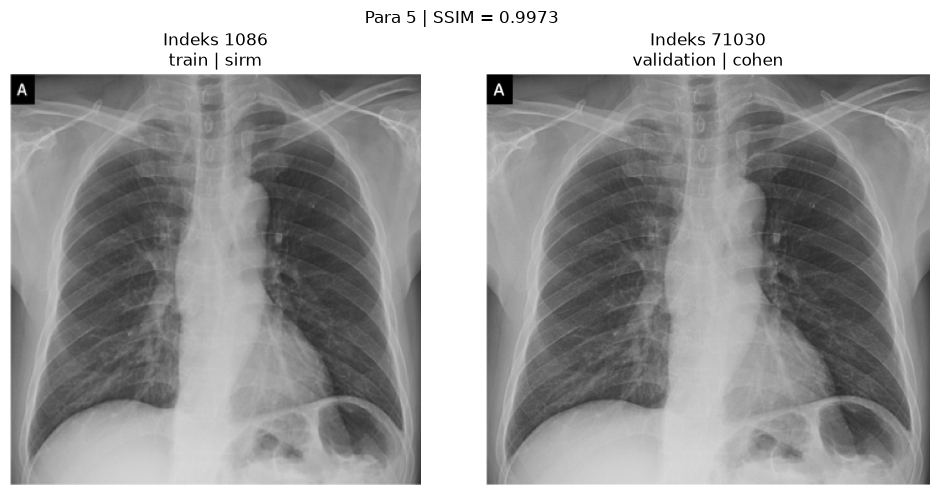

In [20]:
for position, pair in ranking.head(5).iterrows():
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    for ax, side in zip(axes, ["a", "b"]):
        split = pair[f"split_{side}"]
        filename = pair[f"filename_{side}"]

        with Image.open(IMAGE_DIRS[split] / filename) as image:
            ax.imshow(image.convert("L"), cmap="gray")

        ax.set_title(
            f"Indeks {pair[f'index_{side}']}\n"
            f"{split} | {pair[f'source_{side}']}"
        )
        ax.axis("off")

    fig.suptitle(f"Para {position + 1} | SSIM = {pair['ssim']:.4f}")
    plt.tight_layout()
    plt.show()

In [21]:
for threshold in [0.99, 0.98, 0.95, 0.90, 0.65]:
    count = ranking["ssim"].ge(threshold).sum()
    print(f"SSIM ≥ {threshold:.2f}: {count} par")

SSIM ≥ 0.99: 20 par
SSIM ≥ 0.98: 24 par
SSIM ≥ 0.95: 46 par
SSIM ≥ 0.90: 51 par
SSIM ≥ 0.65: 66 par


In [22]:
review_pairs = ranking.loc[ranking["ssim"] >= 0.65].copy()
review_pairs["decision"] = "nieocenione"

print("Pary do przeglądu:", len(review_pairs))

Pary do przeglądu: 66


### Ręczne ocenianie części niedokładnych kopii

In [23]:
# current_dir = Path.cwd().resolve()
# PROJECT_DIR = next(
#     (
#         folder
#         for folder in [current_dir, *current_dir.parents]
#         if (folder / "PROJECT_RULES.md").is_file()
#     ),
#     None,
# )

# if PROJECT_DIR is None:
#     raise FileNotFoundError("Nie znaleziono głównego katalogu repozytorium.")

# REVIEW_FILE = DATA_DIR / "audit_review" / "pair_decisions.csv"
# REVIEW_FILE.parent.mkdir(parents=True, exist_ok=True)

# review_pairs = ranking.loc[ranking["ssim"] >= 0.65].copy()

# def pair_key(row):
#     members = sorted([
#         (str(row["split_a"]), str(row["filename_a"])),
#         (str(row["split_b"]), str(row["filename_b"])),
#     ])
#     return repr(members)

# review_pairs["pair_key"] = review_pairs.apply(pair_key, axis=1)
# assert review_pairs["pair_key"].is_unique

# review_pairs["decision"] = ""
# review_pairs["decision_text"] = ""

# decision_labels = {
#     "0": "rozne",
#     "1": "kopia",
#     "2": "niepewne",
# }

# if REVIEW_FILE.is_file():
#     saved = pd.read_csv(
#         REVIEW_FILE,
#         dtype=str,
#         keep_default_na=False,
#     ).set_index("pair_key")

#     if not saved.index.is_unique:
#         raise ValueError("Plik ocen zawiera powtarzające się klucze par.")

#     review_pairs["decision"] = (
#         review_pairs["pair_key"].map(saved["decision"]).fillna("")
#     )
#     review_pairs["decision_text"] = (
#         review_pairs["decision"].map(decision_labels).fillna("")
#     )

#     invalid = ~review_pairs["decision"].isin(["", "0", "1", "2"])
#     if invalid.any():
#         raise ValueError("Plik zawiera decyzję inną niż 0, 1 lub 2.")


# def save_review():
#     temporary_file = REVIEW_FILE.with_suffix(".tmp")
#     review_pairs.to_csv(temporary_file, index=False, encoding="utf-8")
#     temporary_file.replace(REVIEW_FILE)


# for position, (pair_id, pair) in enumerate(review_pairs.iterrows(), start=1):
#     if pair["decision"] != "":
#         continue

#     clear_output(wait=True)

#     fig, axes = plt.subplots(1, 2, figsize=(12, 6))

#     for ax, side in zip(axes, ["a", "b"]):
#         split = pair[f"split_{side}"]
#         filename = pair[f"filename_{side}"]

#         with Image.open(IMAGE_DIRS[split] / filename) as image:
#             ax.imshow(image.convert("L"), cmap="gray")

#         ax.set_title(
#             f"Indeks {pair[f'index_{side}']}\n"
#             f"{split} | {pair[f'label_{side}']} | "
#             f"{pair[f'source_{side}']}"
#         )
#         ax.axis("off")

#     fig.suptitle(
#         f"Para {position}/{len(review_pairs)} | "
#         f"ID rankingu {pair_id} | SSIM = {pair['ssim']:.4f}"
#     )
#     plt.tight_layout()
#     display(fig)
#     plt.close(fig)

#     print("0 — różne zdjęcia | 1 — kopia | 2 — niepewne | q — zakończ")

#     while True:
#         decision = input("Twoja decyzja: ").strip().lower()

#         if decision in decision_labels or decision == "q":
#             break

#         print("Wpisz 0, 1, 2 albo q.")

#     if decision == "q":
#         break

#     review_pairs.loc[pair_id, "decision"] = decision
#     review_pairs.loc[pair_id, "decision_text"] = decision_labels[decision]
#     save_review()

# clear_output(wait=True)

# print("Zapisane oceny:")
# display(
#     review_pairs["decision_text"]
#     .replace("", "nieocenione")
#     .value_counts()
#     .rename("liczba_par")
# )
# print(f"Plik ocen: {REVIEW_FILE}")

In [24]:
review_pairs = pd.read_csv(
    REVIEW_FILE,
    dtype=str,
    keep_default_na=False,
)

required_columns = {
    "pair_key", "split_a", "filename_a",
    "split_b", "filename_b", "decision",
}

missing_columns = required_columns - set(review_pairs.columns)
if missing_columns:
    raise ValueError(f"Brak wymaganych kolumn: {sorted(missing_columns)}")

if review_pairs["pair_key"].duplicated().any():
    raise ValueError("Plik zawiera powtarzające się pary.")

if not review_pairs["decision"].isin(["0", "1", "2"]).all():
    raise ValueError("Każda para musi mieć decyzję 0, 1 lub 2.")

review_pairs["ssim"] = pd.to_numeric(review_pairs["ssim"])

review_pairs["decision_text"] = review_pairs["decision"].map({
    "0": "różne zdjęcia",
    "1": "kopia",
    "2": "niepewne",
})

print(f"Wczytano {len(review_pairs)} ocenionych par.")
display(
    review_pairs["decision_text"]
    .value_counts()
    .rename("liczba_par")
)

Wczytano 66 ocenionych par.


decision_text
kopia            54
różne zdjęcia    12
Name: liczba_par, dtype: int64

In [25]:
print("Zakres zapisanego przeglądu:")
print("Liczba ocenionych par:", len(review_pairs))
print("Najniższy SSIM:", pd.to_numeric(review_pairs["ssim"]).min())

# Każde ID początkowo tworzy osobną grupę.
parent = {
    patient_id: patient_id
    for patient_id in audit["patient_id"].unique()
}

def find(patient_id):
    while parent[patient_id] != patient_id:
        parent[patient_id] = parent[parent[patient_id]]
        patient_id = parent[patient_id]
    return patient_id

def connect(patient_ids):
    roots = sorted({find(patient_id) for patient_id in patient_ids})
    for root in roots[1:]:
        parent[root] = roots[0]


# Powiązania z dokładnych kopii, również tych już wykluczonych.
for _, group in audit.dropna(subset=["pixel_hash"]).groupby("pixel_hash"):
    if group["patient_id"].nunique() > 1:
        connect(group["patient_id"])


# Wyszukiwanie wpisów według podzbioru i nazwy pliku.
lookup = audit.set_index(["split", "filename"])
assert lookup.index.is_unique

confirmed_pairs = review_pairs.loc[
    review_pairs["decision"] == "1"
].copy()

for _, pair in confirmed_pairs.iterrows():
    key_a = (pair["split_a"], pair["filename_a"])
    key_b = (pair["split_b"], pair["filename_b"])

    connect([
        lookup.loc[key_a, "patient_id"],
        lookup.loc[key_b, "patient_id"],
    ])


# Korekta całych grup powiązanych ID.
resolved = clean.copy()
resolved["group_id"] = resolved["patient_id"].map(find)

priority = {"test": 0, "validation": 1, "train": 2}
resolved["priority"] = resolved["split"].map(priority)

preferred = resolved.groupby("group_id")["priority"].transform("min")
keep = resolved["priority"].eq(preferred)

excluded_by_group = resolved.loc[~keep].drop(columns="priority").copy()
final_data = resolved.loc[keep].drop(columns="priority").copy()

# Weryfikacja rozłączności i dokładnych kopii.
assert final_data.groupby("group_id")["split"].nunique().le(1).all()
assert final_data["pixel_hash"].is_unique
assert final_data["file_hash"].is_unique

print("\nDodatkowe wykluczenia po powiązaniu ID:")
display(
    excluded_by_group.groupby("split").agg(
        zdjecia=("filename", "size"),
        id_pacjentow=("patient_id", "nunique"),
    ).reindex(["train", "validation", "test"], fill_value=0)
)

print("Podział po korekcie:")
display(
    final_data.groupby("split").agg(
        zdjecia=("filename", "size"),
        zapisane_id_pacjentow=("patient_id", "nunique"),
        grupy_powiazanych_id=("group_id", "nunique"),
    ).reindex(["train", "validation", "test"])
)

display(
    pd.crosstab(final_data["split"], final_data["label"])
    .reindex(["train", "validation", "test"])
)

print("Łącznie wykluczono wpisów:", len(audit) - len(final_data))

Zakres zapisanego przeglądu:
Liczba ocenionych par: 66
Najniższy SSIM: 0.6538113023035046

Dodatkowe wykluczenia po powiązaniu ID:


,zdjecia,id_pacjentow
split,,
train,56,54
validation,10,1
test,0,0


Podział po korekcie:


,zdjecia,zapisane_id_pacjentow,grupy_powiazanych_id
split,,,
train,67782,35402,35400
validation,8451,5162,5161
test,8466,4722,4721


label,negative,positive
split,,
train,10662,57120
validation,4232,4219
test,4237,4229


Łącznie wykluczono wpisów: 119


In [26]:
retained = set(zip(final_data["split"], final_data["filename"]))

remaining_cross_split_copies = []

for _, pair in confirmed_pairs.iterrows():
    key_a = (pair["split_a"], pair["filename_a"])
    key_b = (pair["split_b"], pair["filename_b"])

    if key_a in retained and key_b in retained and key_a[0] != key_b[0]:
        remaining_cross_split_copies.append((key_a, key_b))

assert not remaining_cross_split_copies
assert set(final_data["split"]) == {"train", "validation", "test"}
assert final_data.groupby("split")["label"].nunique().eq(2).all()

print("Kontrole końcowe zakończone poprawnie.")

Kontrole końcowe zakończone poprawnie.


### Liczba przykładów i rozkład klas

In [27]:
final_class_counts = pd.crosstab(
    final_data["split"], final_data["label"]
).reindex(["train", "validation", "test"])

display(final_class_counts)

display(
    final_class_counts.div(
        final_class_counts.sum(axis=1), axis=0
    ).mul(100).round(2)
)

display(
    pd.crosstab(
        [final_data["split"], final_data["source"]],
        final_data["label"],
    )
)

label,negative,positive
split,,
train,10662,57120
validation,4232,4219
test,4237,4229


label,negative,positive
split,,
train,15.73,84.27
validation,50.08,49.92
test,50.05,49.95


label                  negative  positive
split      source                        
test       bimcv           4037      4029
           ricord             0       200
           rsna             200         0
train      actmed            78        23
           bimcv            647     42475
           cohen            219       246
           fig1               0        21
           ricord             0       828
           rsna            9718         0
           sirm               0       831
           stonybrook         0     12696
validation actmed            29         2
           bimcv            257      3132
           cohen             77        19
           fig1               0         2
           ricord             0        61
           rsna            3869         0
           sirm               0        65
           stonybrook         0       938

In [28]:
current_dir = Path.cwd().resolve()
PROJECT_DIR = next(
    (
        folder
        for folder in [current_dir, *current_dir.parents]
        if (folder / "PROJECT_RULES.md").is_file()
    ),
    None,
)

if PROJECT_DIR is None:
    raise FileNotFoundError("Nie znaleziono katalogu repozytorium.")

SPLITS_DIR = PROJECT_DIR / "splits"
SPLITS_DIR.mkdir(exist_ok=True)

assert final_data["filename"].notna().all()
assert final_data["group_id"].notna().all()
assert final_data["filename"].is_unique
assert final_data.groupby("group_id")["split"].nunique().le(1).all()

outputs = {}

for split in ["train", "validation", "test"]:
    frame = (
        final_data.loc[
            final_data["split"] == split,
            ["filename", "group_id"],
        ]
        .rename(columns={"filename": "id"})
        .sort_values("id")
    )

    outputs[SPLITS_DIR / f"{split}_ids.csv"] = frame.to_csv(index=False)

for path, content in outputs.items():
    if path.exists() and path.read_text(encoding="utf-8") != content:
        raise RuntimeError(f"Istnieje plik z innym podziałem: {path}")

for path, content in outputs.items():
    if not path.exists():
        with path.open("x", encoding="utf-8", newline="") as file:
            file.write(content)

    saved = pd.read_csv(path, dtype=str)
    print(
        f"{path.name}: {len(saved):,} zdjęć, "
        f"{saved['group_id'].nunique():,} grup"
    )

train_ids.csv: 67,782 zdjęć, 35,400 grup
validation_ids.csv: 8,451 zdjęć, 5,161 grup
test_ids.csv: 8,466 zdjęć, 4,721 grup
